# PhytoSentinel: ResNet50 fine-tuning on PlantVillage (Kaggle GPU)
Fixes over `02_train_model.ipynb`: `resnet50.preprocess_input` instead of `rescale=1/255`,
no augmentation on val/test, stratified 70/15/15 train/val/test split (test untouched until the end),
two-phase training (frozen base + head, then conv5 unfrozen at LR 1e-5 with early stopping on val).

*Run on Kaggle (2x Tesla T4 available, single-GPU training). Outputs below are the run's stdout log and saved figures, attached after download because the Kaggle CLI returns the log rather than the executed notebook.*

In [1]:
import os, json, time, glob, subprocess
import numpy as np
import tensorflow as tf
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, top_k_accuracy_score,
                             classification_report, confusion_matrix)

T0 = time.time()
SEED = 42
IMG = 224
BATCH = 64
HEAD_EPOCHS = 5
FT_EPOCHS = 10
OUT = "/kaggle/working"
tf.keras.utils.set_random_seed(SEED)
tf.keras.mixed_precision.set_global_policy("mixed_float16")
gpus = tf.config.list_physical_devices("GPU")
print("TF", tf.__version__, "| GPUs:", gpus)
try:
    GPU_NAME = subprocess.check_output(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"], text=True).strip()
except Exception as e:
    GPU_NAME = f"none ({e})"
print("GPU:", GPU_NAME)
assert gpus, "No GPU visible - refusing to train on CPU"

TF 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
GPU: Tesla T4
Tesla T4


In [2]:
# Locate the `color` folder (mount path differs between Kaggle image versions) and list structure
for root in sorted(glob.glob("/kaggle/input/*")) + sorted(glob.glob("/kaggle/input/*/*")) + sorted(glob.glob("/kaggle/input/*/*/*")):
    print(root)
cands = sorted(p for p in glob.glob("/kaggle/input/**/color", recursive=True) if os.path.isdir(p))
print("color dirs found:", cands)
DATA_DIR = cands[0]
CLASSES = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
paths, labels = [], []
for i, c in enumerate(CLASSES):
    fs = sorted(f for f in os.listdir(os.path.join(DATA_DIR, c)) if f.lower().endswith((".jpg", ".jpeg", ".png")))
    paths += [os.path.join(DATA_DIR, c, f) for f in fs]
    labels += [i] * len(fs)
paths, labels = np.array(paths), np.array(labels)
NUM_CLASSES = len(CLASSES)
print(f"{NUM_CLASSES} classes, {len(paths)} images")
assert NUM_CLASSES == 38

/kaggle/input/datasets
/kaggle/input/datasets/abdallahalidev
/kaggle/input/datasets/abdallahalidev/plantvillage-dataset
color dirs found: ['/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color', '/kaggle/input/datasets/abdallahalidev/plantvillage-dataset/plantvillage dataset/color']
38 classes, 54305 images


In [3]:
# Stratified 70/15/15 split, fixed seed
p_tr, p_tmp, y_tr, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_va, p_te, y_va, y_te = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
SPLITS = {"train": len(p_tr), "val": len(p_va), "test": len(p_te)}
print(SPLITS)
assert not (set(p_tr) & set(p_va) or set(p_tr) & set(p_te) or set(p_va) & set(p_te))

cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_tr)
CLASS_WEIGHT = dict(enumerate(cw))

AUTOTUNE = tf.data.AUTOTUNE
PRE = tf.keras.applications.resnet50.preprocess_input
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
])

def load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG, IMG))
    return tf.cast(tf.round(img), tf.uint8), y

def make_ds(p, y, train):
    ds = tf.data.Dataset.from_tensor_slices((p, y)).map(load, num_parallel_calls=AUTOTUNE).cache()
    if train:
        ds = ds.shuffle(4096, seed=SEED)
    ds = ds.batch(BATCH)
    if train:
        ds = ds.map(lambda x, l: (PRE(augment(tf.cast(x, tf.float32), training=True)), l), num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(lambda x, l: (PRE(tf.cast(x, tf.float32)), l), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(p_tr, y_tr, True), make_ds(p_va, y_va, False), make_ds(p_te, y_te, False)

{'train': 38013, 'val': 8146, 'test': 8146}


In [4]:
inputs = tf.keras.Input((IMG, IMG, 3))
base = tf.keras.applications.ResNet50(include_top=False, weights="imagenet", input_tensor=inputs)
base.trainable = False
x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(x)
model = tf.keras.Model(inputs, outputs)

def compile_(lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.SparseTopKCategoricalAccuracy(5, name="top5")])

# Phase 1: frozen base, train head
compile_(1e-3)
h1 = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, class_weight=CLASS_WEIGHT, verbose=2)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
594/594 - 683s - 1s/step - accuracy: 0.8303 - loss: 0.6932 - top5: 0.9586 - val_accuracy: 0.9173 - val_loss: 0.2644 - val_top5: 0.9946
Epoch 2/5
594/594 - 210s - 354ms/step - accuracy: 0.9339 - loss: 0.2338 - top5: 0.9974 - val_accuracy: 0.9400 - val_loss: 0.1816 - val_top5: 0.9974
Epoch 3/5
594/594 - 209s - 353ms/step - accuracy: 0.9466 - loss: 0.1826 - top5: 0.9982 - val_accuracy: 0.9346 - val_loss: 0.1863 - val_top5: 0.9979
Epoch 4/5
594/594 - 211s - 355ms/step - accuracy: 0.9502 - loss: 0.1606 - top5: 0.9987 - val_accuracy: 0.9482 - val_loss: 0.1543 - val_top5: 0.9979
Epoch 5/5
594/594 - 206s - 347ms/step - accuracy: 0.9540 - loss: 0.1487 - top5: 0.9989 - val_accuracy: 0.9424 - val_loss: 0.1675 - val_top5: 0.9989


In [5]:
# Phase 2: unfreeze conv5 block; BatchNorm stays frozen (inference mode)
base.trainable = True
for layer in base.layers:
    layer.trainable = layer.name.startswith("conv5_") and not isinstance(layer, tf.keras.layers.BatchNormalization)
print("trainable weights:", len(model.trainable_weights))
compile_(1e-5)
es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
h2 = model.fit(train_ds, validation_data=val_ds, epochs=FT_EPOCHS, class_weight=CLASS_WEIGHT,
               callbacks=[es], verbose=2)
EPOCHS_RUN = {"phase1_head": len(h1.history["loss"]), "phase2_finetune": len(h2.history["loss"])}
print(EPOCHS_RUN)

trainable weights: 22
Epoch 1/10
594/594 - 251s - 423ms/step - accuracy: 0.9686 - loss: 0.0977 - top5: 0.9995 - val_accuracy: 0.9612 - val_loss: 0.1128 - val_top5: 0.9991
Epoch 2/10
594/594 - 214s - 360ms/step - accuracy: 0.9755 - loss: 0.0742 - top5: 0.9997 - val_accuracy: 0.9680 - val_loss: 0.0878 - val_top5: 0.9995
Epoch 3/10
594/594 - 213s - 359ms/step - accuracy: 0.9798 - loss: 0.0629 - top5: 0.9998 - val_accuracy: 0.9731 - val_loss: 0.0800 - val_top5: 0.9995
Epoch 4/10
594/594 - 205s - 345ms/step - accuracy: 0.9832 - loss: 0.0523 - top5: 0.9998 - val_accuracy: 0.9783 - val_loss: 0.0661 - val_top5: 0.9999
Epoch 5/10
594/594 - 206s - 347ms/step - accuracy: 0.9857 - loss: 0.0436 - top5: 0.9998 - val_accuracy: 0.9777 - val_loss: 0.0643 - val_top5: 0.9998
Epoch 6/10
594/594 - 208s - 351ms/step - accuracy: 0.9868 - loss: 0.0412 - top5: 0.9999 - val_accuracy: 0.9773 - val_loss: 0.0699 - val_top5: 1.0000
Epoch 7/10
594/594 - 208s - 351ms/step - accuracy: 0.9878 - loss: 0.0366 - top5: 0.9

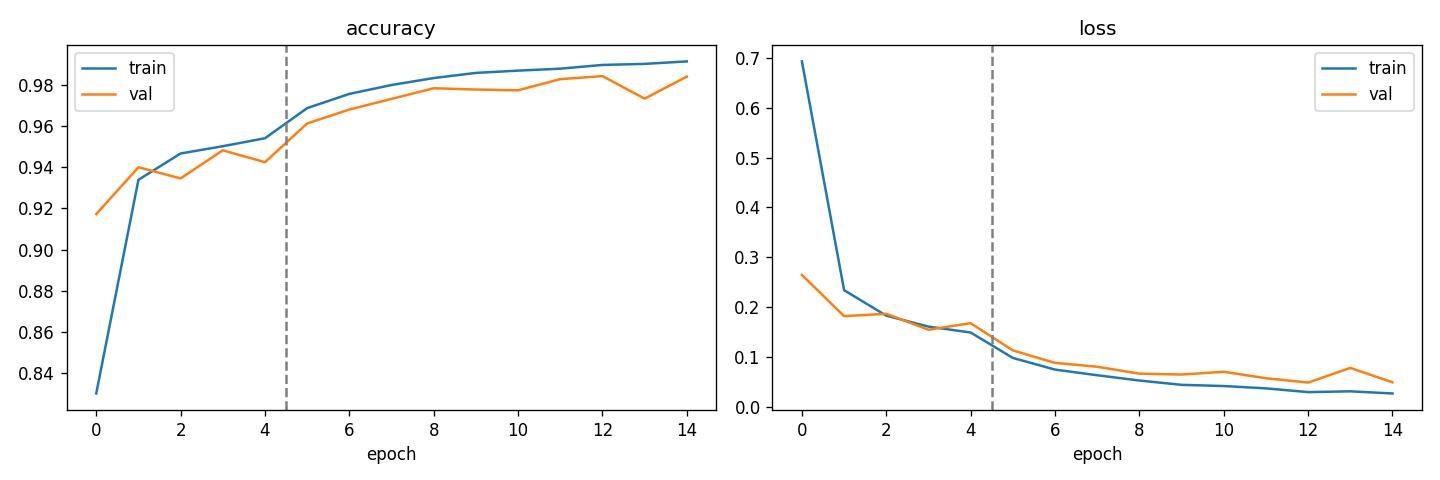

In [6]:
hist = {k: h1.history[k] + h2.history[k] for k in ("accuracy", "val_accuracy", "loss", "val_loss")}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, m in enumerate(("accuracy", "loss")):
    ax[i].plot(hist[m], label="train"); ax[i].plot(hist["val_" + m], label="val")
    ax[i].axvline(EPOCHS_RUN["phase1_head"] - 0.5, ls="--", c="gray")
    ax[i].set_title(m); ax[i].set_xlabel("epoch"); ax[i].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=120); plt.show()

In [7]:
# Final evaluation on the untouched test split
val_acc = float(model.evaluate(val_ds, verbose=0)[1])
probs = model.predict(test_ds, verbose=0)
pred = probs.argmax(1)
WALL = time.time() - T0
metrics = {
    "test_accuracy": float(accuracy_score(y_te, pred)),
    "test_macro_f1": float(f1_score(y_te, pred, average="macro")),
    "test_weighted_f1": float(f1_score(y_te, pred, average="weighted")),
    "test_top5_accuracy": float(top_k_accuracy_score(y_te, probs, k=5, labels=np.arange(NUM_CLASSES))),
    "val_accuracy_restored_best": val_acc,
    "splits": SPLITS, "split_seed": SEED, "num_classes": NUM_CLASSES,
    "epochs_run": EPOCHS_RUN,
    "wall_time_minutes_train_and_eval": round(WALL / 60, 1),
    "gpu": GPU_NAME, "tensorflow": tf.__version__,
    "per_class": classification_report(y_te, pred, target_names=CLASSES, digits=4, output_dict=True),
}
print(json.dumps({k: v for k, v in metrics.items() if k != "per_class"}, indent=2))
print(classification_report(y_te, pred, target_names=CLASSES, digits=4))
with open(f"{OUT}/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
with open(f"{OUT}/class_names.json", "w") as f:
    json.dump(CLASSES, f)
model.save(f"{OUT}/phytosentinel_resnet50.keras")

{
  "test_accuracy": 0.985268843604223,
  "test_macro_f1": 0.9807764953689868,
  "test_weighted_f1": 0.985314302272255,
  "test_top5_accuracy": 0.9995089614534741,
  "val_accuracy_restored_best": 0.9841639995574951,
  "splits": {
    "train": 38013,
    "val": 8146,
    "test": 8146
  },
  "split_seed": 42,
  "num_classes": 38,
  "epochs_run": {
    "phase1_head": 5,
    "phase2_finetune": 10
  },
  "wall_time_minutes_train_and_eval": 63.4,
  "gpu": "Tesla T4\nTesla T4",
  "tensorflow": "2.21.0"
}
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9495    1.0000    0.9741        94
                                 Apple___Black_rot     1.0000    0.9892    0.9946        93
                          Apple___Cedar_apple_rust     1.0000    0.9756    0.9877        41
                                   Apple___healthy     0.9959    0.9959    0.9959       246
                               Blueb

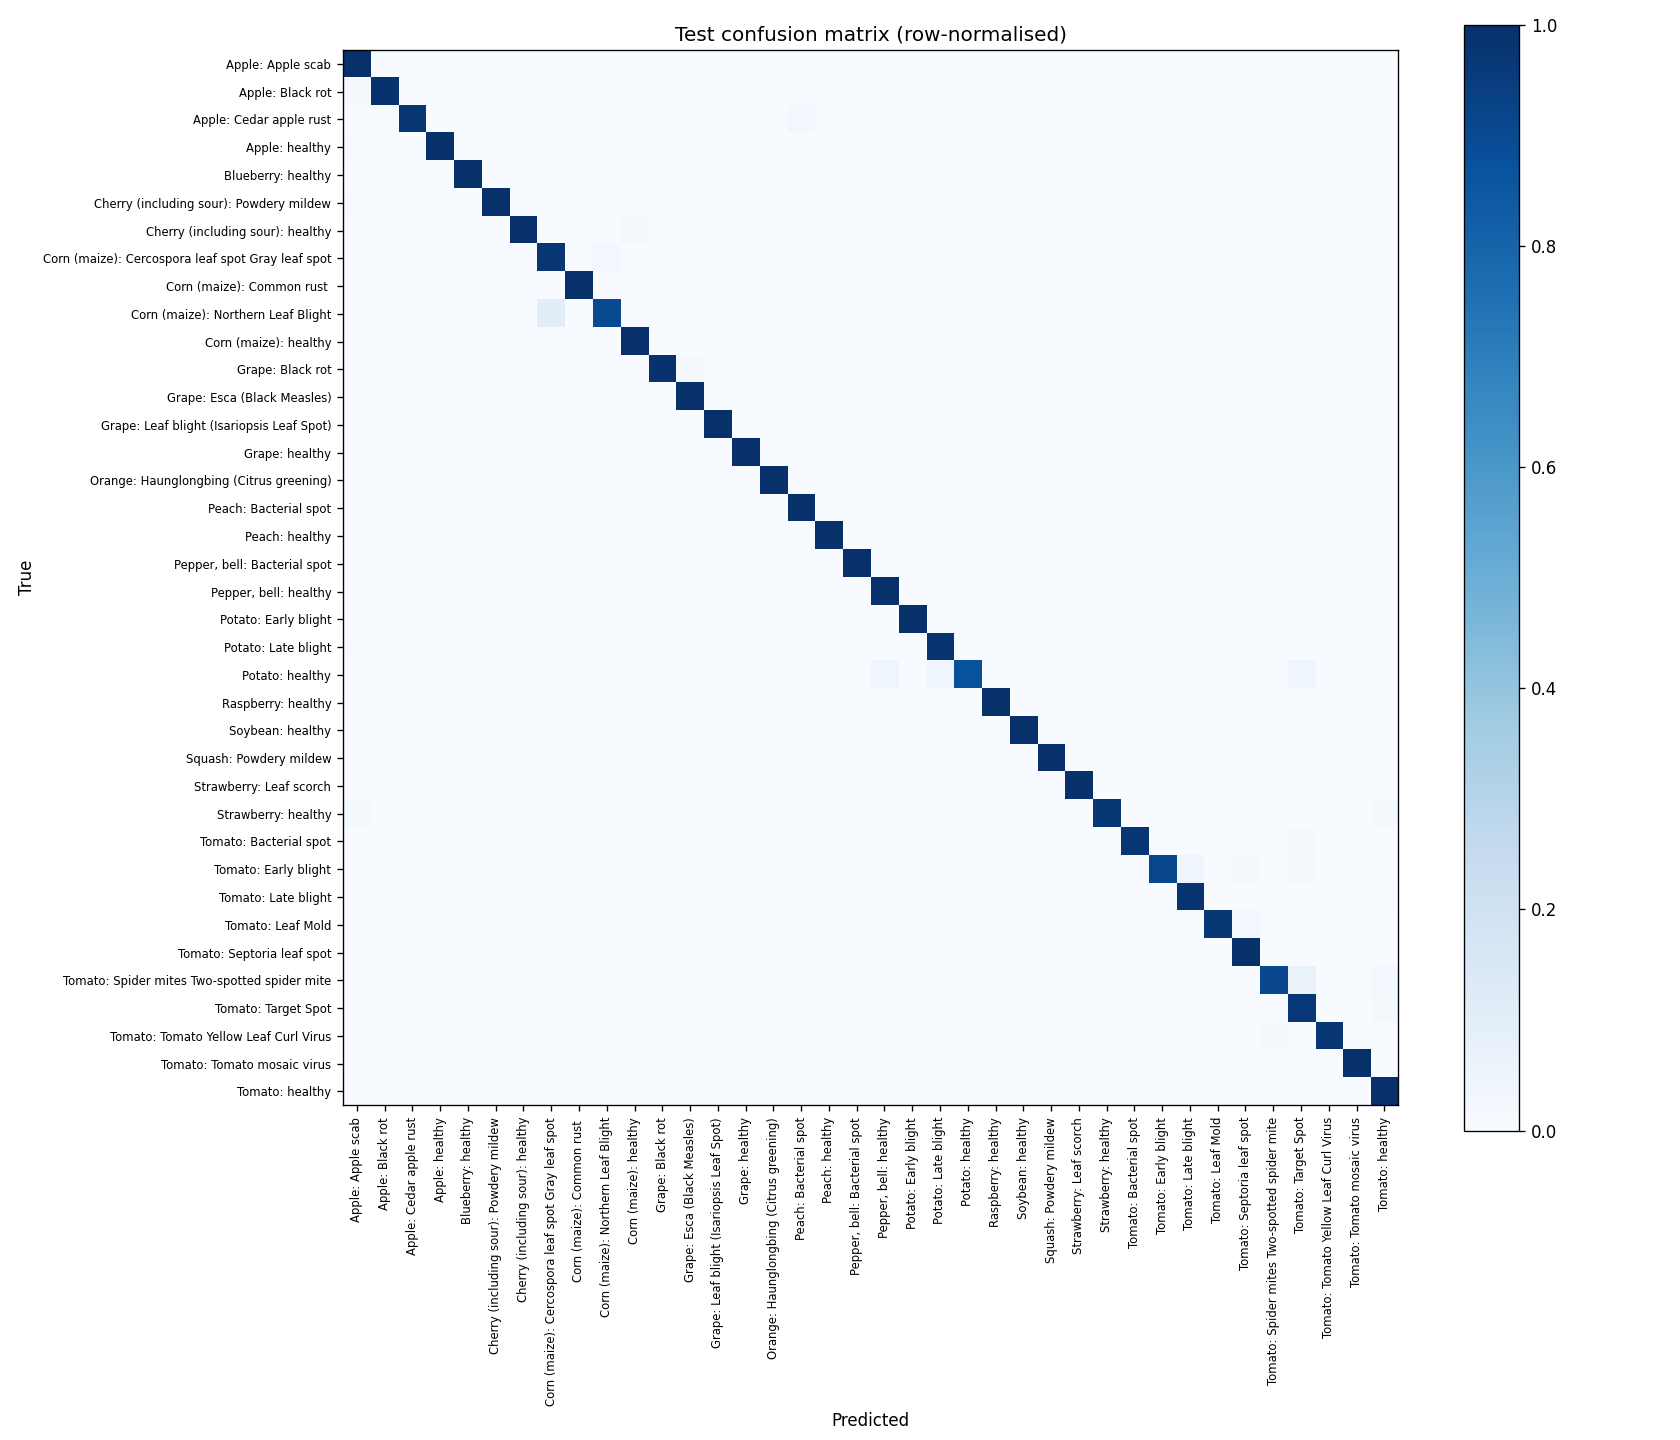

In [8]:
cm = confusion_matrix(y_te, pred, normalize="true")
plt.figure(figsize=(14, 12))
plt.imshow(cm, cmap="Blues", vmin=0, vmax=1); plt.colorbar()
short = [c.replace("___", ": ").replace("_", " ") for c in CLASSES]
plt.xticks(range(NUM_CLASSES), short, rotation=90, fontsize=7); plt.yticks(range(NUM_CLASSES), short, fontsize=7)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Test confusion matrix (row-normalised)")
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrix.png", dpi=120); plt.show()

done, total minutes: 63.5


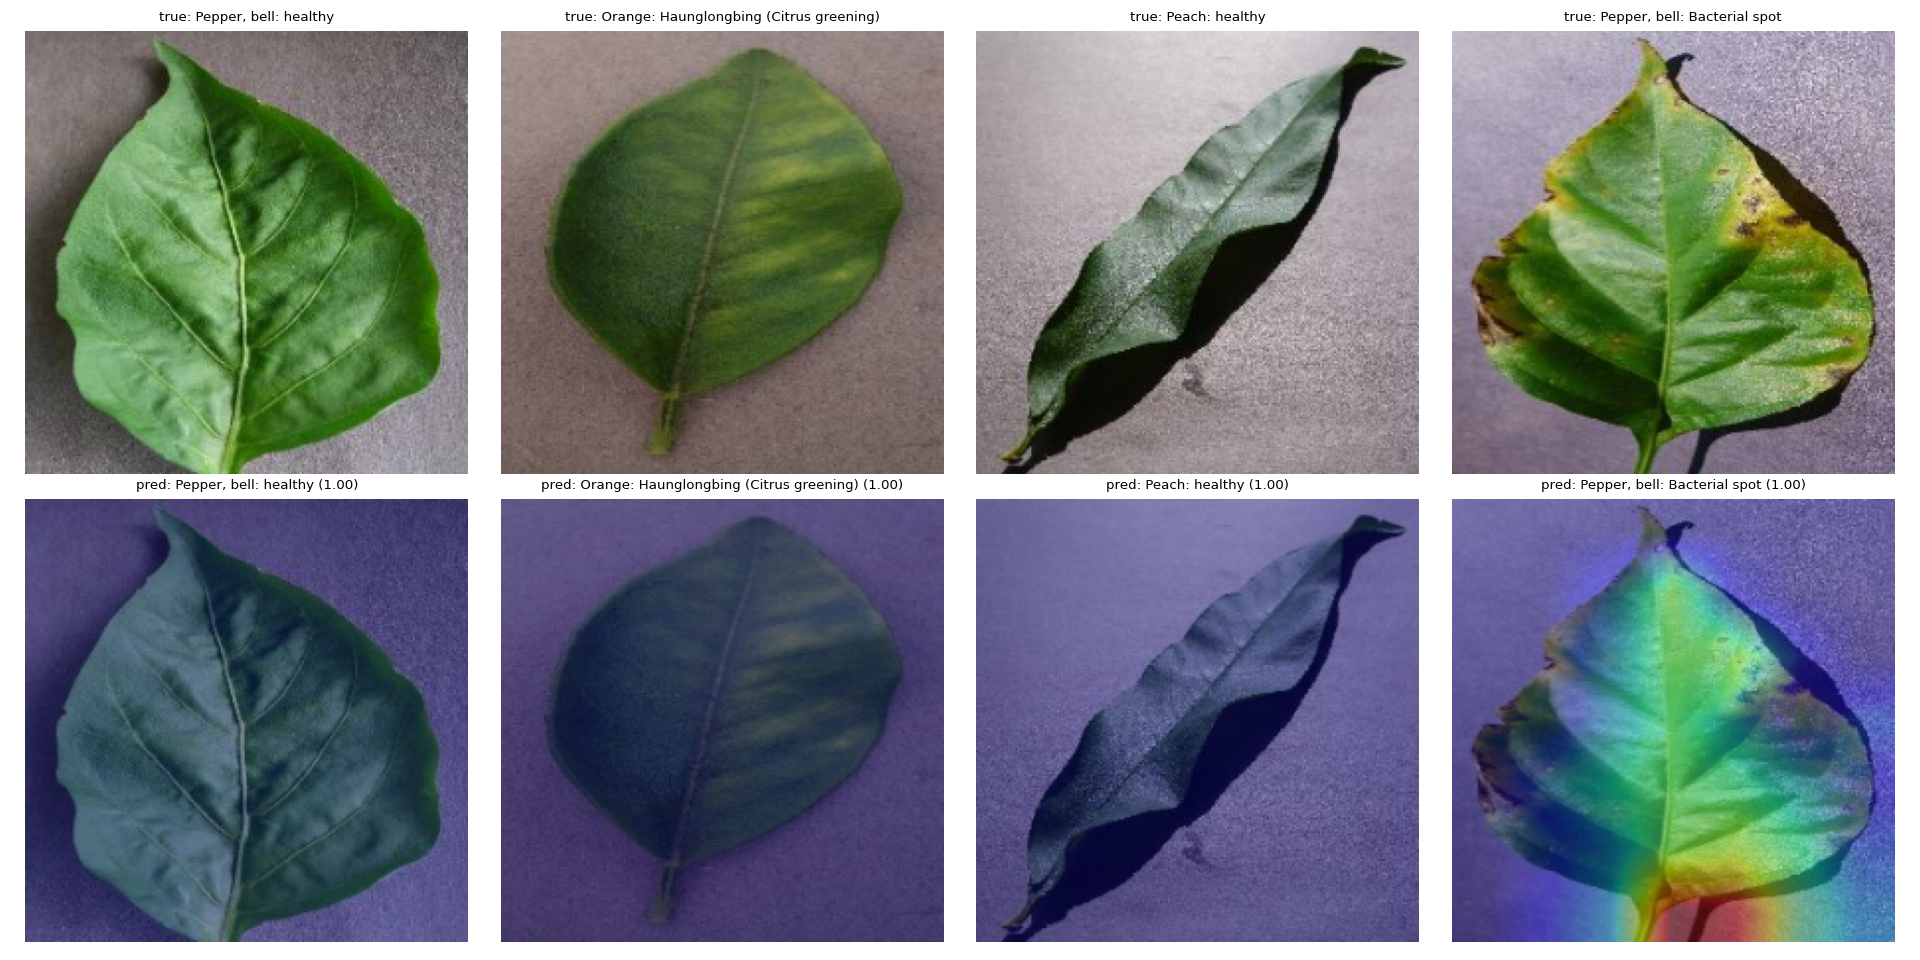

In [9]:
# Grad-CAM on 4 random test images
grad_model = tf.keras.Model(model.inputs, [model.get_layer("conv5_block3_out").output, model.output])
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for j, k in enumerate(rng.choice(len(p_te), 4, replace=False)):
    raw = load(p_te[k], 0)[0].numpy()
    xin = PRE(raw[None].astype("float32"))
    with tf.GradientTape() as tape:
        conv, pr = grad_model(xin)
        c = int(tf.argmax(pr[0]))
        score = pr[:, c]
    g = tf.cast(tape.gradient(score, conv), tf.float32)
    conv = tf.cast(conv, tf.float32)
    w = tf.reduce_mean(g, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv[0] * w, -1)).numpy()
    cam = cam / (cam.max() + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG, IMG)).numpy()[..., 0]
    axes[0, j].imshow(raw); axes[0, j].set_title(f"true: {short[y_te[k]]}", fontsize=8)
    axes[1, j].imshow(raw); axes[1, j].imshow(cam, cmap="jet", alpha=0.4)
    axes[1, j].set_title(f"pred: {short[c]} ({float(pr[0, c]):.2f})", fontsize=8)
    for a in axes[:, j]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT}/gradcam_samples.png", dpi=120); plt.show()
print("done, total minutes:", round((time.time() - T0) / 60, 1))